# LexiPath: supervised prediction and unsupervised learner profiles

This notebook explains the submitted implementation using **recorded TRAIN/DEV experiments**.
It does not fit a model, change model selection, read TEST examples, or claim a real learning gain.
Outputs were executed with the project Python environment. Open in Jupyter/VS Code with that environment to rerun.

The instructor examples motivate clear data-flow diagrams and measured accuracy/loss plots.
Our estimators use scikit-learn optimization, not a five-epoch DistilBERT loop.
Per-iteration loss trajectories were not recorded: we plot real final results for each controlled run.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'outputs/dev_feature_experiments/comparison.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/pilot.py').exists(), 'Run from the project root or notebooks directory.'
OUT = ROOT / 'outputs/presentation_plots'
OUT.mkdir(exist_ok=True)
def read(path):
    return json.loads((ROOT / path).read_text(encoding='utf-8'))
experiment = read('outputs/dev_feature_experiments/comparison.json')
baseline = read('outputs/dev_baseline_comparison/comparison.json')
cluster = read('outputs/kmeans_first_run/comparison.json')
audit = read('outputs/dev_feature_experiments/training_audit.json')
print('TRAIN targets:', experiment['train_targets'])
print('DEV targets:', experiment['dev_targets'])
print('Same 200 learners later in time; no new-student evaluation.')


TRAIN targets: 151967
DEV targets: 23583
Same 200 learners later in time; no new-student evaluation.


## 1. What each supervised training run changed

All variants keep logistic regression and its training settings. Only the feature groups change.
Counts and smoothed rates describe completed interactions **before** the predicted answer.
Smoothed rate = (past correct + 1) / (past count + 2).

In [2]:
variants = ['original', 'format_history', 'recent_history', 'format_and_recent']
names = ['LR6', 'LR10: format', 'LR8: recent', 'LR12: both']
table = pd.DataFrame([
    dict(model=name, raw_features=audit['fits'][key]['raw_feature_count'],
         dev_accuracy=experiment['metrics'][key]['accuracy_at_0_5'],
         dev_log_loss=experiment['metrics'][key]['log_loss'],
         dev_auc=experiment['metrics'][key]['roc_auc_correct_positive'])
    for key, name in zip(variants, names)
])
print(table.round(5).to_string(index=False))
print('Models selected with DEV; transformations fitted only on TRAIN.')


       model  raw_features  dev_accuracy  dev_log_loss  dev_auc
         LR6             6       0.81949       0.41628  0.75219
LR10: format            10       0.82801       0.40265  0.77160
 LR8: recent             8       0.82089       0.41397  0.75704
  LR12: both            12       0.82894       0.40038  0.77580
Models selected with DEV; transformations fitted only on TRAIN.


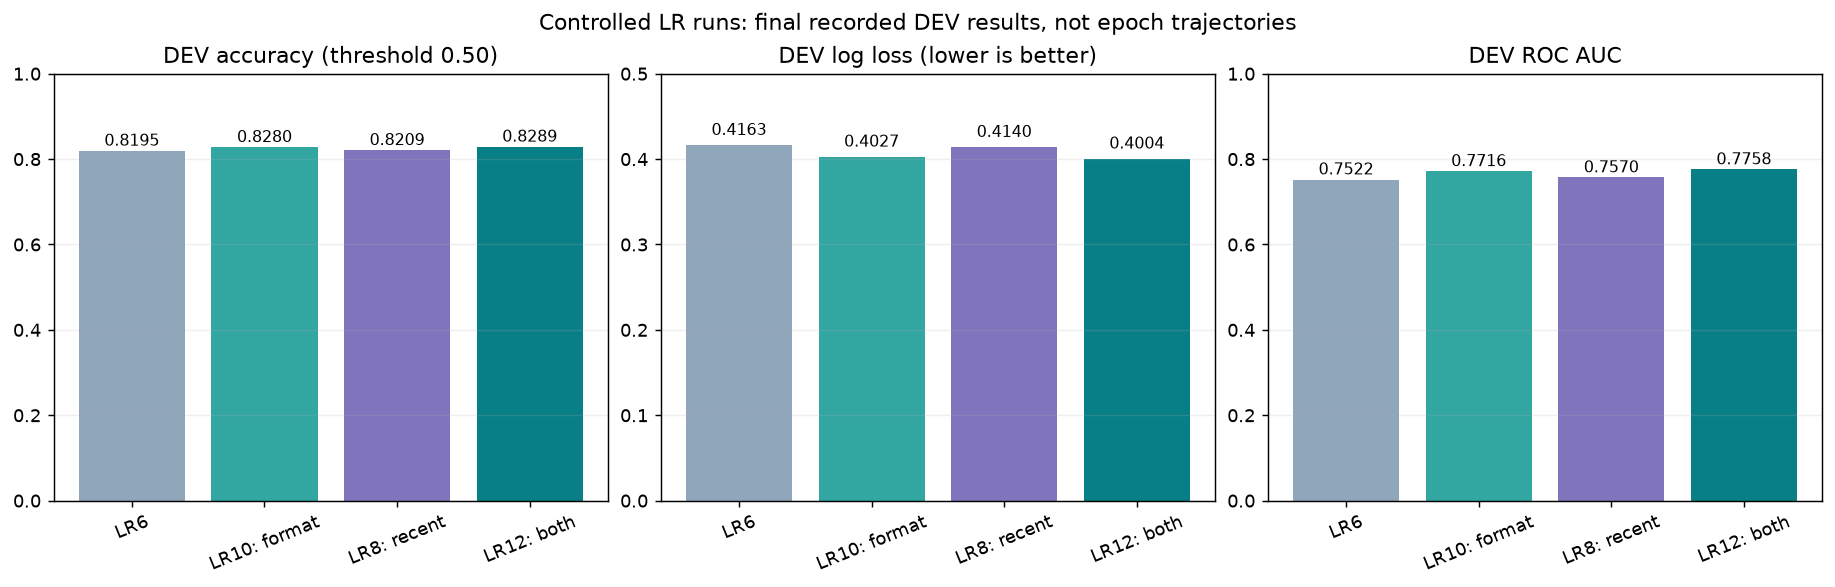

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)
for ax, metric, title in zip(axes,
    ['dev_accuracy', 'dev_log_loss', 'dev_auc'],
    ['DEV accuracy (threshold 0.50)', 'DEV log loss (lower is better)', 'DEV ROC AUC']):
    values = table[metric].to_numpy()
    ax.bar(names, values, color=['#90a6ba', '#32a6a0', '#8074bd', '#087e86'])
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=22)
    ax.set_ylim(0, 1 if metric != 'dev_log_loss' else .5)
    ax.grid(axis='y', alpha=.2)
    for i, v in enumerate(values): ax.text(i, v+.012, f'{v:.4f}', ha='center', fontsize=9)
fig.suptitle('Controlled LR runs: final recorded DEV results, not epoch trajectories')
fig.savefig(OUT / 'lr_run_metrics_en.png', dpi=180)
plt.show()


Accuracy alone is insufficient because most targets are correct. Log loss evaluates probabilities;
AUC evaluates ranking, and is not an accuracy percentage. LR12 has the lowest DEV loss among these runs.
This predictive improvement does not establish that the selected tutoring activities cause more learning.

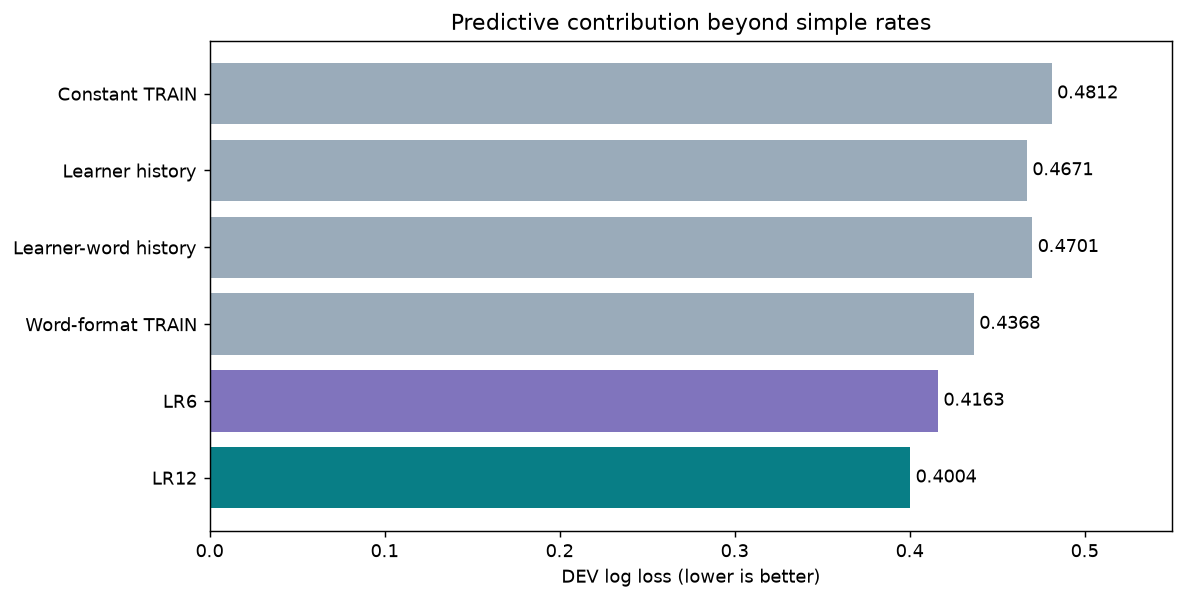

In [4]:
keys = ['constant_train', 'learner_history', 'learner_word_history', 'word_format_train']
labels = ['Constant TRAIN', 'Learner history', 'Learner-word history', 'Word-format TRAIN']
losses = [baseline['metrics'][k]['log_loss'] for k in keys]
labels += ['LR6', 'LR12']
losses += [experiment['metrics']['original']['log_loss'], experiment['metrics']['format_and_recent']['log_loss']]
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.barh(labels, losses, color=['#9aabba']*4 + ['#8074bd', '#087e86'])
for i, v in enumerate(losses): ax.text(v+.003, i, f'{v:.4f}', va='center')
ax.set_xlim(0, .55); ax.invert_yaxis()
ax.set_xlabel('DEV log loss (lower is better)'); ax.set_title('Predictive contribution beyond simple rates')
fig.savefig(OUT / 'baseline_loss_en.png', dpi=180)
plt.show()


## 2. Error detection and optimization logs

At the fixed 0.50 threshold, many real errors remain undetected. Tutoring need therefore follows actual control responses.
The optimization iteration count reports solver work; it is not an epoch count or a quality score.

Caught errors: 916/4375 = 20.94%
format_history solver iterations: [240] fit seconds: 2.001 convergence warnings: []
recent_history solver iterations: [180] fit seconds: 1.47 convergence warnings: []
format_and_recent solver iterations: [243] fit seconds: 2.26 convergence warnings: []


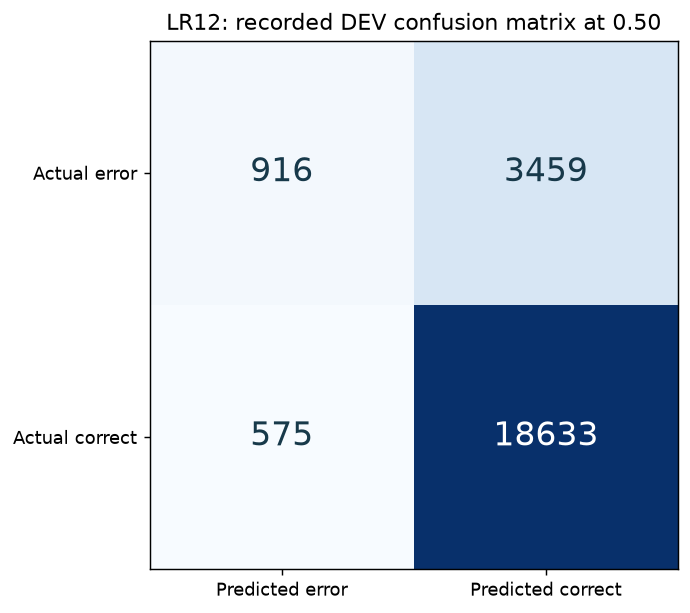

In [5]:
m = experiment['metrics']['format_and_recent']
cm = np.asarray(m['confusion_rows_actual_cols_predicted_error_correct'])
fig, ax = plt.subplots(figsize=(6, 4.6), constrained_layout=True)
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2): ax.text(j, i, str(cm[i,j]), ha='center', va='center', fontsize=18,
                              color='white' if cm[i,j] > cm.max()/2 else '#17394a')
ax.set_xticks([0,1], ['Predicted error', 'Predicted correct'])
ax.set_yticks([0,1], ['Actual error', 'Actual correct'])
ax.set_title('LR12: recorded DEV confusion matrix at 0.50')
fig.savefig(OUT / 'lr12_confusion_en.png', dpi=180); plt.show()
print(f"Caught errors: {m['caught_errors']}/{m['actual_errors']} = {m['error_recall_at_0_5']:.2%}")
for key in variants[1:]:
    fit = audit['fits'][key]
    print(key, 'solver iterations:', fit['iterations'], 'fit seconds:', round(fit['fit_seconds'], 3),
          'convergence warnings:', fit['convergence_warnings'])


## 3. Unsupervised task: compare k=2,3,4

Each TRAIN learner contributes two real last-six success rates. No expected learner-group label is supplied.
Silhouette assesses internal separation, not correctness or learning benefit. A larger k naturally tends to reduce inertia.

 k  silhouette   inertia  smallest_group
 2     0.38860 252.60407              77
 3     0.45691 141.48636              40
 4     0.47378 107.23803              18
Selected k: 4 | learners: 200 | distinct profile points: 29
 group  students  text_target_accuracy  listen_target_accuracy
     1        18                0.6481                  0.2963
     2        64                0.5625                  0.8568
     3        42                0.9365                  0.5437
     4        76                0.9101                  0.9298


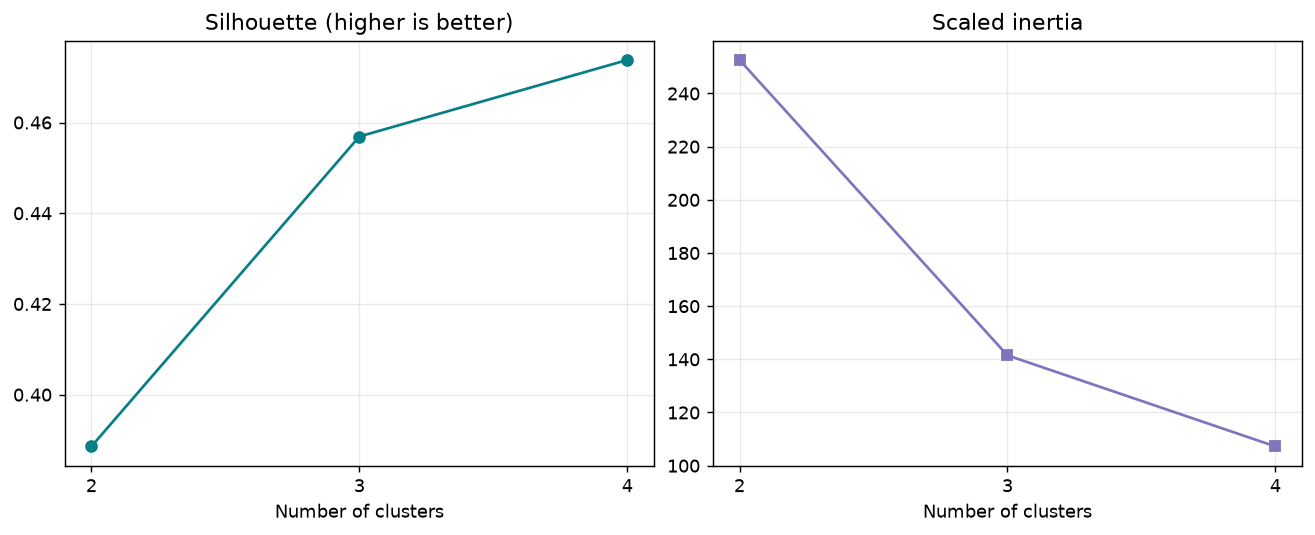

In [6]:
candidates = pd.DataFrame([
    dict(k=c['k'], silhouette=c['silhouette'], inertia=c['inertia_scaled'],
         smallest_group=c['smallest_cluster']) for c in cluster['candidates']
])
print(candidates.round(5).to_string(index=False))
print('Selected k:', cluster['selected_k'], '| learners:', cluster['learners'],
      '| distinct profile points:', cluster['distinct_profiles'])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].plot(candidates.k, candidates.silhouette, 'o-', color='#087e86')
axes[1].plot(candidates.k, candidates.inertia, 's-', color='#8074bd')
axes[0].set_title('Silhouette (higher is better)'); axes[1].set_title('Scaled inertia')
for ax in axes: ax.set_xticks([2,3,4]); ax.set_xlabel('Number of clusters'); ax.grid(alpha=.25)
fig.savefig(OUT / 'kmeans_selection_en.png', dpi=180); plt.show()
chosen = next(c for c in cluster['candidates'] if c['selected'])
print(pd.DataFrame([dict(group=g['display_group'], students=g['students'],
                        **g['center_original_scale']) for g in chosen['groups']]).round(4).to_string(index=False))


## 4. Student evidence and the model bridge

The synthetic demonstration includes a writing error, target-specific visual/audio teaching, supported retry,
and unassisted checks. Picture-choice and supported responses stay outside native model history.
Only real text writing and listening-writing enter the two model histories.
The last-six profile [1.00, 0.50] maps to source Group 3. Delayed retention is still pending.

Synthetic demonstration: Ayşe · Sentetik sunum senaryosu
Native text records: 8
Native listening-writing records: 8
Last-six profile: {'text_target_accuracy': 1.0, 'listen_target_accuracy': 0.5} | group: 3
Learning-goal evidence: 12 | delayed stage: waiting


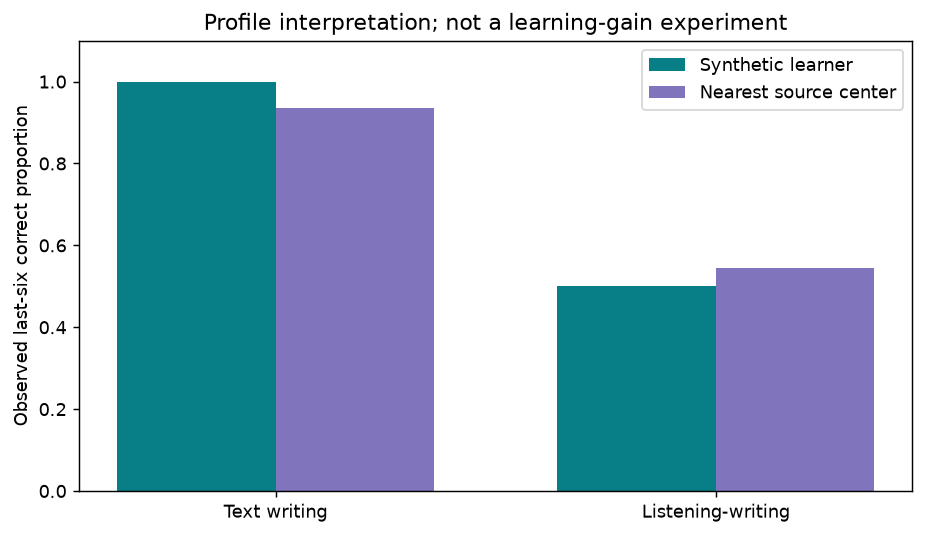

In [7]:
demo = read('outputs/final_scenario/scenario_output.json')
profile = demo['model_audit']['kmeans']
print('Synthetic demonstration:', demo['name'])
print('Native text records:', demo['model_audit']['lr_native_writing_records'])
print('Native listening-writing records:', demo['model_audit']['lr_native_listen_write_records'])
print('Last-six profile:', profile['features'], '| group:', profile['group']['number'])
print('Learning-goal evidence:', len(demo['outcomes']), '| delayed stage:', demo['stage'])
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
own = [profile['features']['text_target_accuracy'], profile['features']['listen_target_accuracy']]
center = [profile['group']['reference_center']['text_target_accuracy'], profile['group']['reference_center']['listen_target_accuracy']]
x=np.arange(2); ax.bar(x-.18, own, .36, label='Synthetic learner', color='#087e86')
ax.bar(x+.18, center, .36, label='Nearest source center', color='#8074bd')
ax.set_xticks(x, ['Text writing', 'Listening-writing']);ax.set_ylim(0,1.1)
ax.set_ylabel('Observed last-six correct proportion');ax.legend()
ax.set_title('Profile interpretation; not a learning-gain experiment')
fig.savefig(OUT / 'student_profile_en.png', dpi=180);plt.show()


## 5. Reproduction and limits

- `train_logistic.py`: historical LR6 training/evaluation protocol (includes the original TEST evaluation).
- `compare_dev_baselines.py`: DEV-only rate comparisons.
- `run_dev_feature_experiments.py`: TRAIN-fit / DEV-selection feature experiments.
- `prepare_profiles.py` and `train_kmeans.py`: TRAIN-only learner profiles and cluster comparison.
- This notebook only reads saved results. It does not automatically invoke any training script.
- Source DEV uses the same learners later in time; it does not validate new learners, Turkish single-word tasks,
  cold-start calibration, real 24-hour retention, or causal tutoring benefit.
